# **Library**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from importlib import reload
from modules import monte_carlo, binomial, comparison
reload(binomial)
reload(comparison)

pd.set_option('display.float_format', '{:,.4f}'.format)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

COLORS = {'Heston MC': 'tab:blue', 'Tree ATM vol': 'tab:red',
          'Tree 70% vol': 'tab:orange', 'Tree implied vol': 'tab:green',
          'Flat MC ATM vol': 'tab:brown', 'Flat MC 70% vol': 'tab:pink'}

# **Model Inputs**

In [3]:
# Heston parameters (from calibration)
V_0 = 0.028319833917909945
KAPPA = 3.4158314637296794
THETA = 0.05471611433894729
ETA = 1.949743914893052
RHO = -0.5449784854430381
heston_parameters = [KAPPA, THETA, ETA, RHO]

M = 20000           # MC paths (same as monte_carlo.ipynb)
SEED = 42
TREE_MULT = 10      # tree steps = TREE_MULT x days to valuation
Z_99 = 2.5758       # 99% two-sided normal quantile, same as monte_carlo.ipynb

surface = pd.read_excel('Data/ATM_IV.xlsx', sheet_name='OVDV')

# **Note Terms**

In [4]:
PRICING_DATE = pd.Timestamp('2026-09-18')
VALUATION_DATE = pd.Timestamp('2030-09-18')
PRINCIPAL = 1000
S0 = 7650.50
CALL_LEVEL = S0
COUPON_LEVEL = 0.7 * S0
COUPON_RATE = 0.02
THRESHOLD_LEVEL = 0.7 * S0
R = 0.0456673       # risk-free rate
Q = 0.01151         # Bloomberg OVME continuous dividend yield to 2030-09-23, as of 2026-09-18

ts = lambda dates: [pd.Timestamp(d) for d in dates]

# coupon observation dates (16)
observation_date = ts(['2026-12-18', '2027-03-18', '2027-06-21', '2027-09-20', '2027-12-20', '2028-03-20', '2028-06-20', '2028-09-18',
                       '2028-12-18', '2029-03-19', '2029-06-18', '2029-09-18', '2029-12-18', '2030-03-18', '2030-06-18', '2030-09-18'])

# autocall observation dates (12)
autocall_date = ts(['2027-09-20', '2027-12-20', '2028-03-20', '2028-06-20', '2028-09-18', '2028-12-18',
                    '2029-03-19', '2029-06-18', '2029-09-18', '2029-12-18', '2030-03-18', '2030-06-18'])

# payment dates (16), one for each observation date
payment_date = ts(['2026-12-23', '2027-03-23', '2027-06-24', '2027-09-23', '2027-12-23', '2028-03-23', '2028-06-23', '2028-09-21',
                   '2028-12-21', '2029-03-22', '2029-06-22', '2029-09-21', '2029-12-21', '2030-03-21', '2030-06-24', '2030-09-23'])

N = (VALUATION_DATE - PRICING_DATE).days
T, delta_t, observation_t, autocall_t, payment_t = monte_carlo.year_fraction(
    N, PRICING_DATE, VALUATION_DATE, observation_date, autocall_date, payment_date)

payoff = dict(observation_t=list(observation_t), autocall_t=list(autocall_t), payment_t=list(payment_t),
              principal=PRINCIPAL, call_level=CALL_LEVEL, coupon_level=COUPON_LEVEL,
              coupon_rate=COUPON_RATE, threshold_level=THRESHOLD_LEVEL)
tree = dict(T=T, s_0=S0, r=R, q=Q, **payoff)
N_TREE = TREE_MULT * N

# **Run All Models**

Heston MC (path cash flows); flat-vol MC at the surface ATM and 70% (barrier) vols (same simulator and seed, with $\eta = 0$ and $v_0 = \theta = \sigma^2$); the tree at the same two vols; and the tree at the *implied flat vol*, i.e. the single vol that makes the tree match the Heston price.

In [5]:
# Heston MC
s_obs = comparison.heston_obs_paths(M, N, delta_t, list(observation_t), S0, V_0, R - Q, heston_parameters, seed=SEED)
mc = comparison.mc_cashflows(s_obs, S0, R, **payoff)

# flat vols from the surface at maturity, and the flat vol that matches the Heston price
vols = {'Tree ATM vol': binomial.surface_vol(surface, T, 1.0),
        'Tree 70% vol': binomial.surface_vol(surface, T, 0.7)}
vols['Tree implied vol'] = comparison.implied_flat_vol(mc['value'].mean(), N_TREE, **tree)

# binomial trees
trees = {label: comparison.crr_event_probs(N_TREE, sigma=v, **tree) for label, v in vols.items()}

# flat-vol MC: eta = 0 and v_0 = theta = sigma^2, so the variance stays at sigma^2 (GBM)
flat = {}
for label, v in [('Flat MC ATM vol', vols['Tree ATM vol']), ('Flat MC 70% vol', vols['Tree 70% vol'])]:
    s_obs_flat = comparison.heston_obs_paths(M, N, delta_t, list(observation_t), S0, v**2, R - Q,
                                             [KAPPA, v**2, 0.0, RHO], seed=SEED)
    flat[label] = comparison.mc_cashflows(s_obs_flat, S0, R, **payoff)
del s_obs_flat

# **1. Price Summary**

In [6]:
v = mc['value']
mc_price, se = v.mean(), v.std(ddof=1) / np.sqrt(len(v))

summary = pd.Series({
    'Heston MC': mc_price,
    'MC std err': se,
    'MC 99% CI low': mc_price - Z_99*se,
    'MC 99% CI high': mc_price + Z_99*se,
    'Flat MC ATM vol': flat['Flat MC ATM vol']['value'].mean(),
    'Flat MC 70% vol': flat['Flat MC 70% vol']['value'].mean(),
    'Tree ATM vol': trees['Tree ATM vol']['value'],
    'Tree 70% vol': trees['Tree 70% vol']['value'],
    'ATM vol': vols['Tree ATM vol'],
    '70% vol': vols['Tree 70% vol'],
    'Implied flat vol': vols['Tree implied vol'],
    'Heston MC - Flat MC ATM': mc_price - flat['Flat MC ATM vol']['value'].mean(),
    'Flat MC ATM - Tree ATM': flat['Flat MC ATM vol']['value'].mean() - trees['Tree ATM vol']['value'],
})
summary

Heston MC                   998.5619
MC std err                    1.1292
MC 99% CI low               995.6533
MC 99% CI high            1,001.4705
Flat MC ATM vol             996.6700
Flat MC 70% vol             967.0466
Tree ATM vol                996.1214
Tree 70% vol                966.2866
ATM vol                       0.2089
70% vol                       0.2540
Implied flat vol              0.2055
Heston MC - Flat MC ATM       1.8919
Flat MC ATM - Tree ATM        0.5485
dtype: float64

## **Price vs Flat Volatility**

Tree price (red) and flat-vol Monte Carlo price (brown, with its 99% CI band) as functions of a single flat vol, against the Heston MC price (blue, with its 99% CI band). The dotted lines mark the surface ATM and 70% moneyness vols.

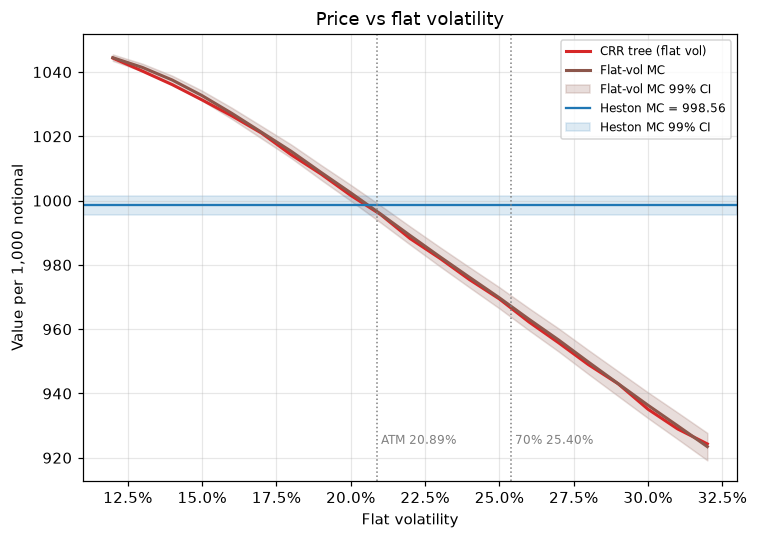

In [7]:
vol_grid = np.linspace(0.12, 0.32, 21)

# tree price at each flat vol
curve = binomial.crr_vols(N_TREE, vol_grid, **tree)

# flat-vol MC price at each flat vol (eta = 0, v_0 = theta = sigma^2), same seed at every vol
flat_mean, flat_hw = [], []
for sigma in vol_grid:
    s_obs_flat = comparison.heston_obs_paths(M, N, delta_t, list(observation_t), S0, sigma**2, R - Q,
                                             [KAPPA, sigma**2, 0.0, RHO], seed=SEED)
    x = comparison.mc_cashflows(s_obs_flat, S0, R, **payoff)['value']
    flat_mean.append(x.mean())
    flat_hw.append(Z_99 * x.std(ddof=1) / np.sqrt(len(x)))
flat_mean, flat_hw = np.array(flat_mean), np.array(flat_hw)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(curve['vol'], curve['Value'], '-', lw=2, color='tab:red', label='CRR tree (flat vol)')
ax.plot(vol_grid, flat_mean, '-', lw=2, color=COLORS['Flat MC ATM vol'], label='Flat-vol MC')
ax.fill_between(vol_grid, flat_mean - flat_hw, flat_mean + flat_hw, color=COLORS['Flat MC ATM vol'], alpha=0.2,
                label='Flat-vol MC 99% CI')
ax.axhline(mc_price, color='tab:blue', label=f'Heston MC = {mc_price:,.2f}')
ax.axhspan(mc_price - Z_99*se, mc_price + Z_99*se, color='tab:blue', alpha=0.15, label='Heston MC 99% CI')
for label, name in [('Tree ATM vol', 'ATM'), ('Tree 70% vol', '70%')]:
    ax.axvline(vols[label], color='grey', ls=':', lw=1)
    ax.text(vols[label], curve['Value'].min(), f' {name} {vols[label]:.2%}', fontsize=8, color='grey')
ax.set_title('Price vs flat volatility')
ax.set_xlabel('Flat volatility')
ax.set_ylabel('Value per 1,000 notional')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# **2. Where the Value Comes From**

PV split into contingent coupons, principal returned at autocall, and principal returned at maturity.

In [8]:
rows = [{'Model': 'Heston MC', 'PV coupons': mc['pv_coupon'].mean(), 'PV autocall principal': mc['pv_call'].mean(),
         'PV maturity principal': mc['pv_maturity'].mean(), 'Total': mc['value'].mean()}]
for label, f in flat.items():
    rows.append({'Model': label, 'PV coupons': f['pv_coupon'].mean(), 'PV autocall principal': f['pv_call'].mean(),
                 'PV maturity principal': f['pv_maturity'].mean(), 'Total': f['value'].mean()})
for label, t in trees.items():
    rows.append({'Model': label, 'PV coupons': t['pv_coupon'], 'PV autocall principal': t['pv_call'],
                 'PV maturity principal': t['pv_maturity'], 'Total': t['value']})
decomp = pd.DataFrame(rows).set_index('Model')
decomp

,PV coupons,PV autocall principal,PV maturity principal,Total
Model,,,,
Heston MC,101.6736,817.6648,79.2235,998.5619
Flat MC ATM vol,118.6075,751.1583,126.9042,996.6700
Flat MC 70% vol,112.1388,727.3383,127.5696,967.0466
Tree ATM vol,119.5863,745.7264,130.8087,996.1214
Tree 70% vol,112.9594,722.6891,130.6382,966.2866
Tree implied vol,120.1647,747.6598,130.7369,998.5614


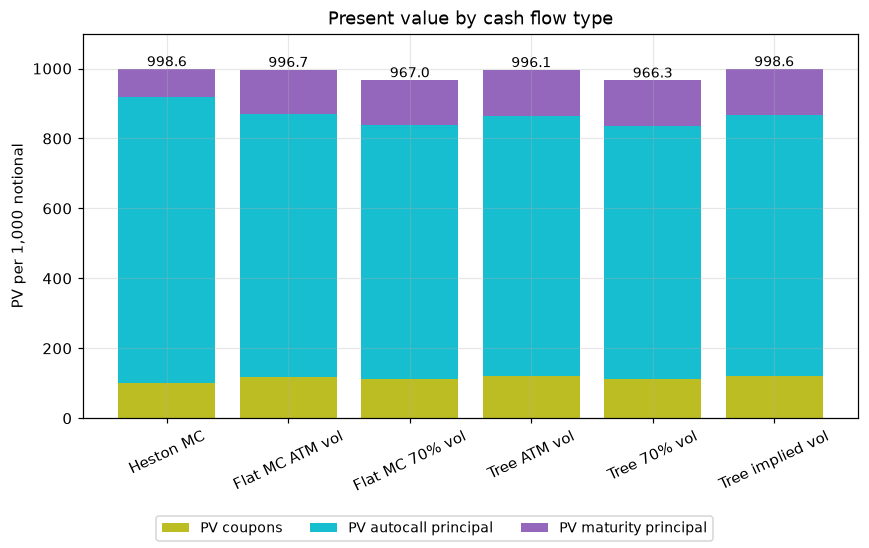

In [9]:
parts = ['PV coupons', 'PV autocall principal', 'PV maturity principal']
part_colors = ['tab:olive', 'tab:cyan', 'tab:purple']

fig, ax = plt.subplots(figsize=(8, 5))
bottom = np.zeros(len(decomp))
for part, c in zip(parts, part_colors):
    ax.bar(decomp.index, decomp[part], bottom=bottom, color=c, label=part)
    bottom += decomp[part].to_numpy()
for x, total in enumerate(decomp['Total']):
    ax.text(x, total + 8, f'{total:,.1f}', ha='center', fontsize=9)
ax.set_title('Present value by cash flow type')
ax.set_ylabel('PV per 1,000 notional')
ax.set_ylim(0, 1100)
ax.tick_params(axis='x', rotation=25)
fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=9)
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

# **3. Autocall and Loss Probabilities**

In [10]:
def mc_stats(m):
    p_call = np.bincount(m['call_date'][m['call_date'] >= 0], minlength=len(observation_t)) / M
    life = np.where(m['call_date'] >= 0, np.asarray(payment_t)[m['call_date']], payment_t[-1])
    return dict(p_call=p_call, p_coupon=m['coupon_paid'].mean(axis=0),
                p_maturity=(m['call_date'] < 0).mean(), p_loss=m['loss'].mean(), life=life.mean())

def tree_stats(t):
    t = dict(t)
    t['life'] = (t['p_call'] * np.asarray(payment_t)).sum() + t['p_maturity'] * payment_t[-1]
    return t

stats = {'Heston MC': mc_stats(mc),
         **{label: mc_stats(f) for label, f in flat.items()},
         **{label: tree_stats(t) for label, t in trees.items()}}

first_call = np.flatnonzero(np.isin(observation_t, autocall_t))[0]
events = pd.DataFrame([{'Model': model,
                        'P(call at 1st call date)': s['p_call'][first_call],
                        'P(called before maturity)': s['p_call'].sum(),
                        'P(reach maturity)': s['p_maturity'],
                        'P(principal loss)': s['p_loss'],
                        'Expected coupons paid': s['p_coupon'].sum(),
                        'Expected life (years)': s['life']} for model, s in stats.items()]).set_index('Model')
events

,P(call at 1st call date),P(called before maturity),P(reach maturity),P(principal loss),Expected coupons paid,Expected life (years)
Model,,,,,,
Heston MC,0.6787,0.8642,0.1358,0.0736,5.3386,1.5981
Flat MC ATM vol,0.5237,0.7985,0.2016,0.1107,6.2663,1.8840
Flat MC 70% vol,0.5023,0.7733,0.2267,0.1503,5.9109,1.9550
Tree ATM vol,0.5170,0.7929,0.2071,0.1121,6.3217,1.9040
Tree 70% vol,0.4964,0.7686,0.2314,0.1522,5.9577,1.9737
Tree implied vol,0.5188,0.7949,0.2051,0.1085,6.3536,1.8981


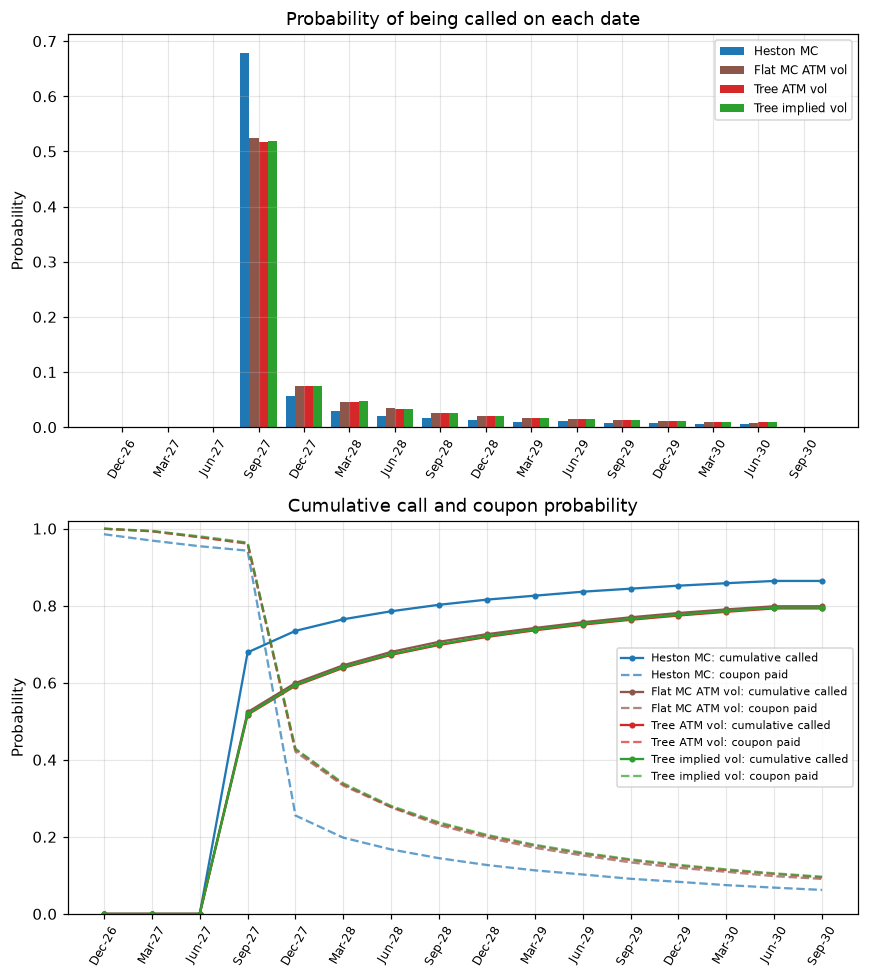

In [11]:
models = ['Heston MC', 'Flat MC ATM vol', 'Tree ATM vol', 'Tree implied vol']
width = 0.2
dates = [d.strftime('%b-%y') for d in observation_date]
x = np.arange(len(dates))

fig, axes = plt.subplots(2, 1, figsize=(8, 9))

ax = axes[0]
for k, model in enumerate(models):
    ax.bar(x + (k - 1.5)*width, stats[model]['p_call'], width, color=COLORS[model], label=model)
ax.set_xticks(x, dates, rotation=60, fontsize=8)
ax.set_title('Probability of being called on each date')
ax.set_ylabel('Probability')
ax.legend(fontsize=8)

ax = axes[1]
for model in models:
    s = stats[model]
    ax.plot(x, np.cumsum(s['p_call']), '-o', ms=3, color=COLORS[model], label=f'{model}: cumulative called')
    ax.plot(x, s['p_coupon'], '--', color=COLORS[model], alpha=0.7, label=f'{model}: coupon paid')
ax.set_xticks(x, dates, rotation=60, fontsize=8)
ax.set_ylim(0, 1.02)
ax.set_title('Cumulative call and coupon probability')
ax.set_ylabel('Probability')
ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

# **4. Distribution of Outcomes**

For notes that are **not called**, the simple return of the index over the note's life, $(S_T - S_0)/S_0$: Heston MC (blue) vs flat-vol MC at the ATM vol (brown), same paths and seed. Heights are the **share of all paths (%)**, so the area left of the $-30\%$ threshold is the probability of a principal loss.

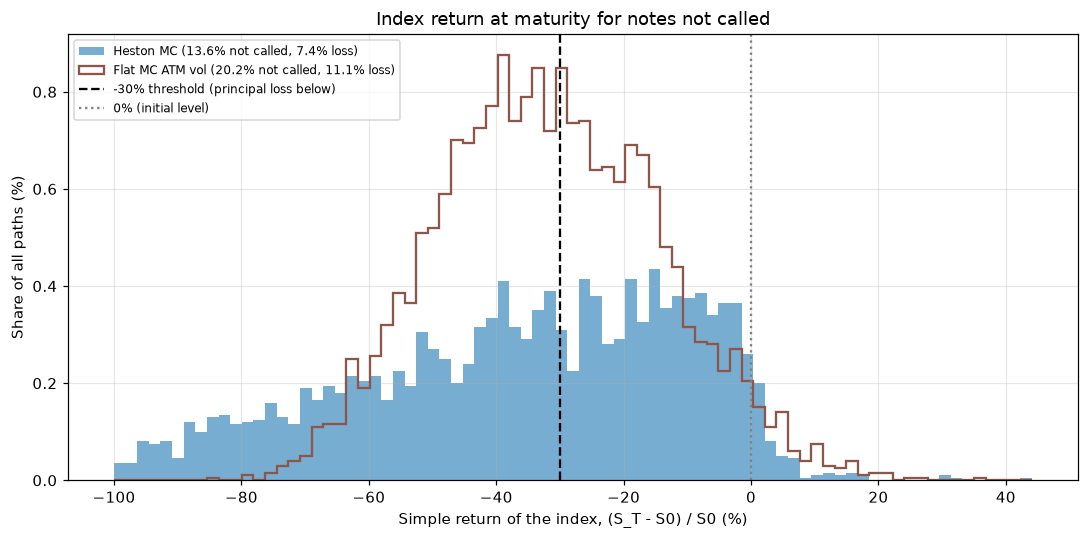

In [12]:
dist_models = [('Heston MC', mc, 'tab:blue'), ('Flat MC ATM vol', flat['Flat MC ATM vol'], COLORS['Flat MC ATM vol'])]

# simple return of the index over the note's life, for notes that are not called
returns = {label: (m['s_T'][m['call_date'] < 0] / S0 - 1) * 100 for label, m, _ in dist_models}
bins = np.linspace(-100, max(r.max() for r in returns.values()), 80)

fig, ax = plt.subplots(figsize=(10, 5))
for label, m, color in dist_models:
    r = returns[label]
    style = dict(alpha=0.6, histtype='bar') if label == 'Heston MC' else dict(histtype='step', lw=1.5)
    ax.hist(r, bins=bins, weights=np.full(len(r), 100 / M), color=color, **style,
            label=f'{label} ({(m["call_date"] < 0).mean():.1%} not called, {m["loss"].mean():.1%} loss)')
ax.axvline(-30, color='black', ls='--', label='-30% threshold (principal loss below)')
ax.axvline(0, color='grey', ls=':', label='0% (initial level)')
ax.set_title('Index return at maturity for notes not called')
ax.set_xlabel('Simple return of the index, (S_T - S0) / S0 (%)')
ax.set_ylabel('Share of all paths (%)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# **5. Numerical Convergence**

Left: Heston MC running mean with 99% CI as paths are added, and the flat-vol MC (ATM vol) running mean. Right: tree price as steps increase (ATM vol and implied vol).

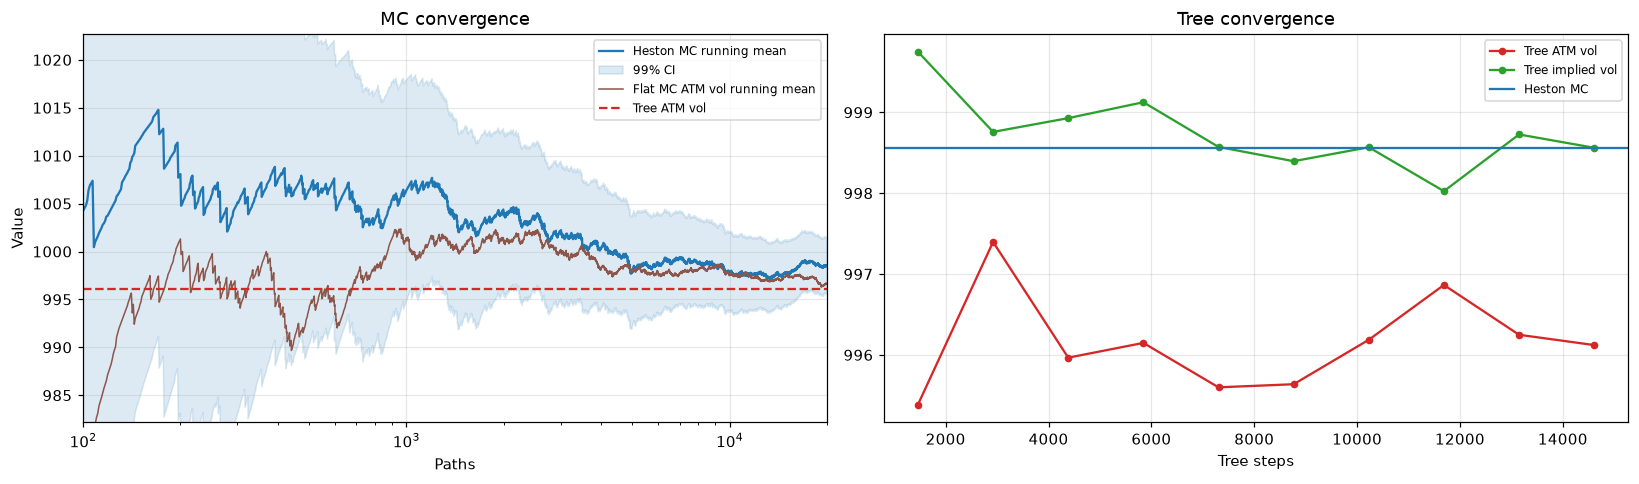

In [13]:
v = mc['value']
m = np.arange(1, len(v) + 1)
running = np.cumsum(v) / m
running_var = (np.cumsum(v**2) - m * running**2) / np.maximum(m - 1, 1)
running_se = np.sqrt(np.maximum(running_var, 0) / m)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

ax = axes[0]
ax.plot(m, running, color='tab:blue', label='Heston MC running mean')
ax.fill_between(m, running - Z_99*running_se, running + Z_99*running_se, color='tab:blue', alpha=0.15, label='99% CI')
flat_v = flat['Flat MC ATM vol']['value']
ax.plot(m, np.cumsum(flat_v) / m, color=COLORS['Flat MC ATM vol'], lw=1, label='Flat MC ATM vol running mean')
ax.axhline(trees['Tree ATM vol']['value'], color='tab:red', ls='--', label='Tree ATM vol')
ax.set_xscale('log')
ax.set_xlim(100, len(v))
ax.set_ylim(running[1000:].min() - 15, running[1000:].max() + 15)
ax.set_title('MC convergence')
ax.set_xlabel('Paths')
ax.set_ylabel('Value')
ax.legend(fontsize=8)

ax = axes[1]
for label in ['Tree ATM vol', 'Tree implied vol']:
    conv = binomial.crr_convergence(N, 10, sigma=vols[label], **tree)
    ax.plot(conv['num_steps'], conv['Value'], '-o', ms=4, color=COLORS[label], label=label)
ax.axhline(v.mean(), color='tab:blue', label='Heston MC')
ax.set_title('Tree convergence')
ax.set_xlabel('Tree steps')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()